In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:

df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")

df

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,...,3,80,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,...,1,80,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,...,2,80,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,...,4,80,0,17,3,2,9,6,0,8


In [3]:

df.shape

(1470, 35)

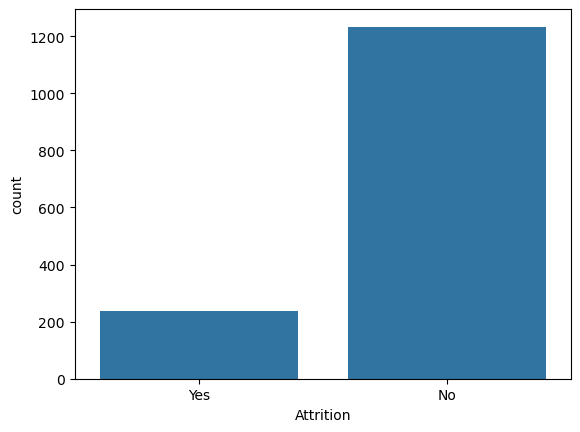

In [4]:

sns.countplot(x='Attrition', data=df)
plt.show()

In [5]:

df.drop(['EmployeeCount', 'EmployeeNumber', 'Over18', 'StandardHours'], axis="columns", inplace=True)

In [6]:

df.shape

(1470, 31)

In [7]:
# Select categorical columns with <= 50 unique values (excluding the target if needed)\

categorical_col = [col for col in df.select_dtypes(include='str').columns if df[col].nunique() <= 50]

print(categorical_col)

['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


In [8]:
# Convert 'Attrition' from 'Yes'/'No' to 1/0

df['Attrition'] = df['Attrition'].map({'Yes': 1, 'No': 0})

In [9]:

df['Attrition'].value_counts()

Attrition
0    1233
1     237
Name: count, dtype: int64

In [10]:
from sklearn.model_selection import train_test_split

X = df.drop("Attrition", axis=1)
y = df["Attrition"]


In [11]:

X_train, X_test, y_train, y_test = train_test_split(  X, y, test_size=0.3, random_state=42, stratify=y)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1029, 30)
Testing data: (441, 30)


In [12]:

categorical_cols = X_train.select_dtypes(
    include=["str", "object", "category"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include="number"
).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)

Categorical columns: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']
Numerical columns: ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [13]:

from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import OneHotEncoder

from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestClassifier

In [14]:

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ("num", "passthrough", numerical_cols)
])

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers co

In [15]:

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [16]:

y_pred = rf_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.8435374149659864


In [17]:

print(classification_report( y_test, y_pred, target_names=["Stayed", "Left"], zero_division=0))

              precision    recall  f1-score   support

      Stayed       0.85      0.98      0.91       370
        Left       0.56      0.13      0.21        71

    accuracy                           0.84       441
   macro avg       0.71      0.55      0.56       441
weighted avg       0.81      0.84      0.80       441



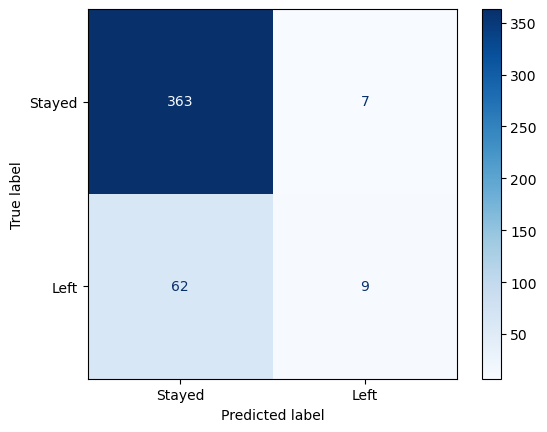

In [18]:

ConfusionMatrixDisplay.from_predictions( y_test, y_pred, display_labels=["Stayed", "Left"], cmap="Blues")
plt.show()

In [19]:
from sklearn.model_selection import StratifiedKFold

cv_strategy = StratifiedKFold( n_splits=5, shuffle=True, random_state=42)

In [20]:
from sklearn.model_selection import RandomizedSearchCV
import numpy as np

param_dist = {
    "model__n_estimators": [100, 200, 300, 500, 700],
    "model__max_features": ["sqrt", None],
    "model__max_depth": [5, 10, 20, 30, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4, 10],
    "model__bootstrap": [True, False]
}

rf_cv = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_dist,
    n_iter=30,
    scoring="f1",
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_cv.fit(X_train, y_train)

print("Best parameters:")
print(rf_cv.best_params_)

print("Best CV F1-score:", rf_cv.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best parameters:
{'model__n_estimators': 100, 'model__min_samples_split': 2, 'model__min_samples_leaf': 10, 'model__max_features': 'sqrt', 'model__max_depth': 10, 'model__bootstrap': False}
Best CV F1-score: 0.5357280487196127


In [21]:
best_model = rf_cv.best_estimator_

y_pred = best_model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed", "Left"],
    zero_division=0
))

Test Accuracy: 0.8276643990929705
              precision    recall  f1-score   support

      Stayed       0.91      0.88      0.90       370
        Left       0.47      0.55      0.51        71

    accuracy                           0.83       441
   macro avg       0.69      0.72      0.70       441
weighted avg       0.84      0.83      0.83       441



In [22]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__n_estimators": [100, 300],
    "model__max_features": ["sqrt", None],
    "model__max_depth": [10, 20, None],
    "model__min_samples_leaf": [1, 4]
}

grid_cv = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    scoring="f1",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1
)

grid_cv.fit(X_train, y_train)

print("Best parameters:", grid_cv.best_params_)
print("Best CV F1-score:", grid_cv.best_score_)

grid_best_model = grid_cv.best_estimator_

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best parameters: {'model__max_depth': 20, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 4, 'model__n_estimators': 300}
Best CV F1-score: 0.487892783250471


In [23]:

if rf_cv.best_score_ >= grid_cv.best_score_:
    best_model = rf_cv.best_estimator_
    print("Selected: Randomized Search")
    print("CV F1-score:", rf_cv.best_score_)
else:
    best_model = grid_cv.best_estimator_
    print("Selected: Grid Search")
    print("CV F1-score:", grid_cv.best_score_)
    

Selected: Randomized Search
CV F1-score: 0.5357280487196127


              precision    recall  f1-score   support

      Stayed       0.91      0.88      0.90       370
        Left       0.47      0.55      0.51        71

    accuracy                           0.83       441
   macro avg       0.69      0.72      0.70       441
weighted avg       0.84      0.83      0.83       441



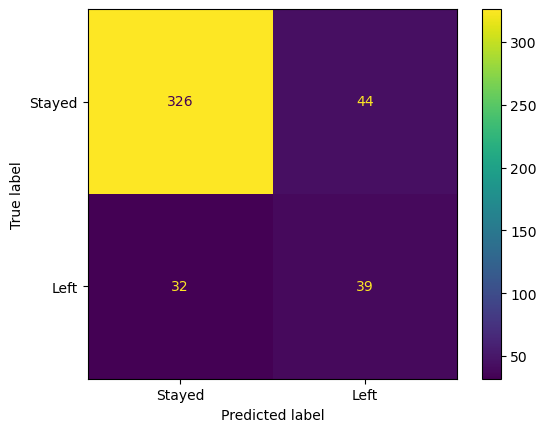

In [24]:
y_pred = best_model.predict(X_test)

print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed", "Left"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Stayed", "Left"]
)

plt.show()

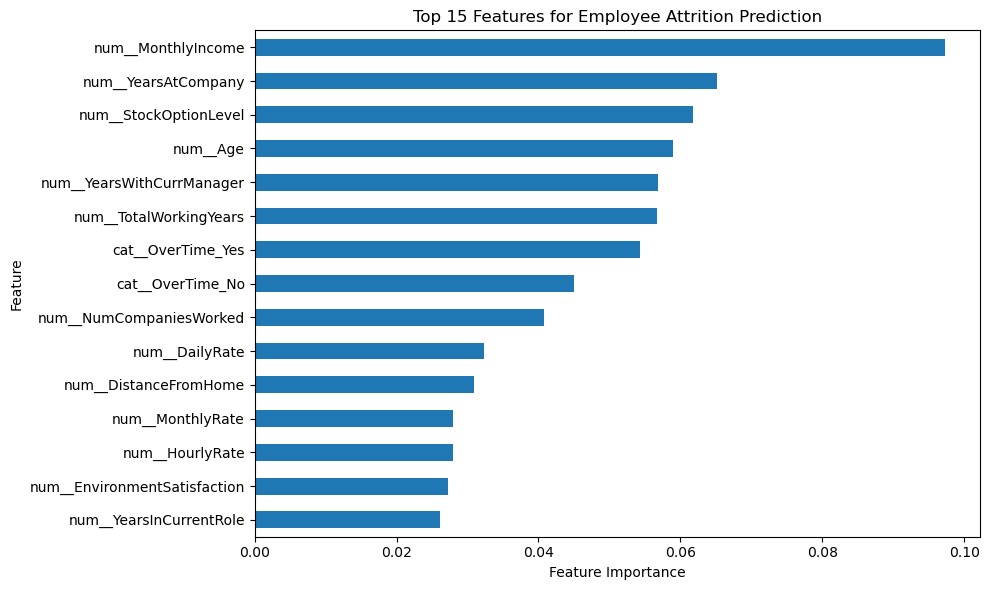

In [25]:
importance = best_model.named_steps["model"].feature_importances_

feature_names = (
    best_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values("Importance", ascending=False)

importance_df.head(15).sort_values("Importance").plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False,
    figsize=(10, 6)
)

plt.title("Top 15 Features for Employee Attrition Prediction")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()